# Notebook 01 — Exploratory Data Analysis (EDA)
## Customer Loyalty & Engagement Assistant

**Objective:** Understand the raw synthetic banking datasets before building customer profiles or ML features.

### What we will investigate
1. Dataset structure, row counts and data types
2. Missing values and duplicate records
3. Customer coverage across event tables
4. Activity, transaction, billing, campaign and communication patterns
5. Relationships and potential data-quality issues
6. Initial observations and decisions for the profiling notebook

> **Important:** This notebook is for understanding the raw data. Do not perform final feature engineering or clustering here. The synthetic `behavioural_archetype_for_validation` column is only for post-hoc sanity checks and must never be used as an ML input feature.


In [ ]:
# 1. Imports, Google Drive connection, and dataset loading

from pathlib import Path
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Mount Google Drive (run this notebook in Google Colab)
from google.colab import drive
drive.mount("/content/drive")

# Find the ZIP wherever it is stored inside MyDrive.
ZIP_NAME = "customer_loyalty_synthetic_20k.zip"
MY_DRIVE = Path("/content/drive/MyDrive")
zip_matches = list(MY_DRIVE.rglob(ZIP_NAME))

if not zip_matches:
    raise FileNotFoundError(
        f"Could not find {ZIP_NAME} inside MyDrive. "
        "Check the ZIP filename and make sure it has finished uploading."
    )

ZIP_PATH = zip_matches[0]
print("ZIP found at:", ZIP_PATH)

# Extract the ZIP into the Colab runtime.
EXTRACT_DIR = Path("/content")
with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

# The ZIP contains a folder named customer_loyalty_synthetic_20k.
DATA_DIR = EXTRACT_DIR / "customer_loyalty_synthetic_20k"

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Expected extracted dataset folder was not found: {DATA_DIR}. "
        "Check the ZIP's internal folder structure."
    )

print("Dataset folder:", DATA_DIR)
print("CSV files found:", len(list(DATA_DIR.glob("*.csv"))))

FILES = {
    "customers": "customers.csv",
    "activity": "monthly_activity.csv",
    "transactions": "transactions.csv",
    "billing": "billing_history.csv",
    "campaigns": "campaign_interactions.csv",
    "communications": "communication_history.csv",
    "campaign_catalogue": "campaign_catalogue.csv",
    "offers": "approved_offers.csv",
    "profile_reference": "customer_profile_features.csv",
    "dictionary": "data_dictionary.csv",
}

def load_csv(filename):
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Could not find {path}")
    return pd.read_csv(path)

data = {name: load_csv(filename) for name, filename in FILES.items()}

for name, df in data.items():
    print(f"{name:20s} {df.shape}")

Mounted at /content/drive
ZIP found at: /content/drive/MyDrive/customer_loyalty_synthetic_20k.zip
Dataset folder: /content/customer_loyalty_synthetic_20k
CSV files found: 10
customers            (20000, 10)
activity             (240000, 7)
transactions         (221203, 6)
billing              (80616, 9)
campaigns            (64287, 6)
communications       (50153, 7)
campaign_catalogue   (6, 7)
offers               (4, 10)
profile_reference    (20000, 31)
dictionary           (9, 4)


## 2. Understand the tables

Each table has a different grain. Before joining anything, understand what one row represents.

- `customers`: one row per customer
- `monthly_activity`: one row per customer per month
- `transactions`: one row per transaction
- `billing`: one row per monthly loan bill
- `campaigns`: one row per campaign interaction
- `communications`: one row per communication event
- `campaign_catalogue`: one row per campaign
- `offers`: one row per offer
- `profile_reference`: one row per customer; reference aggregation only


In [ ]:
# 2.1 Shape and sample records

for name, df in data.items():
    print("\\n" + "="*80)
    print(name.upper(), "| shape:", df.shape)
    display(df.head(5))


\n================================================================================
CUSTOMERS | shape: (20000, 10)


,customer_id,join_date,tenure_months,primary_product,customer_status,preferred_channel,marketing_consent,monthly_contact_cap,statement_cycle,has_loan
0,CUST000001,2026-07-04,4,Premium,New,App,True,4,Monthly,False
1,CUST000002,2023-09-18,38,Current,Active,Email,True,4,Monthly,False
2,CUST000003,2026-05-05,6,Salary,Active,App,True,5,Monthly,False
3,CUST000004,2026-07-04,4,Savings,New,Email,True,2,Monthly,False
4,CUST000005,2024-08-13,27,Salary,Active,WhatsApp,True,4,Monthly,False


\n================================================================================
ACTIVITY | shape: (240000, 7)


,customer_id,activity_month,active_days,login_count,app_sessions,service_usage_count,engagement_score
0,CUST000001,2025-11,0,0,2,0,42.80
1,CUST000002,2025-11,16,25,12,10,54.80
2,CUST000003,2025-11,15,21,13,12,38.90
3,CUST000004,2025-11,6,8,6,4,36.80
4,CUST000005,2025-11,30,53,25,20,84.70


\n================================================================================
TRANSACTIONS | shape: (221203, 6)


,transaction_id,customer_id,transaction_date,transaction_type,amount_inr,transaction_status
0,TX000000001,CUST000001,2025-12-17,UPI,214.53,Successful
1,TX000000002,CUST000001,2025-12-20,Card,180.50,Successful
2,TX000000003,CUST000001,2026-06-08,IMPS,79.47,Successful
3,TX000000004,CUST000001,2026-09-23,NEFT,98.01,Successful
4,TX000000005,CUST000001,2026-01-24,Bill Payment,136.03,Successful


... (10 outputs left out)

\n================================================================================
PROFILE_REFERENCE | shape: (20000, 31)


,customer_id,join_date,tenure_months,primary_product,customer_status,preferred_channel,marketing_consent,monthly_contact_cap,statement_cycle,has_loan,transaction_count,total_transaction_value_inr,avg_transaction_value_inr,last_transaction_date,avg_monthly_active_days,avg_monthly_logins,avg_engagement_score,latest_engagement_score,total_bills,overdue_bill_count,avg_days_overdue,total_outstanding_inr,campaigns_received,campaigns_accepted,communications_count,marketing_communications,recency_days,campaign_response_rate,payment_consistency_pct,behavioural_archetype_for_validation,synthetic_ground_truth_note
0,CUST000001,2026-07-04,4,Premium,New,App,True,4,Monthly,False,9.00,"2,367.32",263.04,2026-09-23,2.25,4.25,43.49,45.80,0.00,0.00,0.00,0.00,4.00,0.00,3.00,0.00,39.00,0.00,100.00,new,Reference-only; exclude from ML inputs
1,CUST000002,2023-09-18,38,Current,Active,Email,True,4,Monthly,False,10.00,"9,320.91",932.09,2026-10-10,11.17,14.67,48.48,48.80,0.00,0.00,0.00,0.00,5.00,2.00,2.00,1.00,22.00,0.40,100.00,declining,Reference-only; exclude from ML inputs
2,CUST000003,2026-05-05,6,Salary,Active,App,True,5,Monthly,False,10.00,"3,283.54",328.35,2026-10-15,15.75,20.75,40.67,47.10,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00,17.00,0.00,100.00,irregular,Reference-only; exclude from ML inputs
3,CUST000004,2026-07-04,4,Savings,New,Email,True,2,Monthly,False,9.00,"1,753.22",194.80,2026-09-15,8.92,13.42,41.80,49.20,0.00,0.00,0.00,0.00,1.00,0.00,2.00,1.00,47.00,0.00,100.00,new,Reference-only; exclude from ML inputs
4,CUST000005,2024-08-13,27,Salary,Active,WhatsApp,True,4,Monthly,False,13.00,"1,931.74",148.60,2026-10-31,27.75,41.92,80.08,72.10,0.00,0.00,0.00,0.00,4.00,2.00,3.00,1.00,1.00,0.50,100.00,loyal,Reference-only; exclude from ML inputs


\n================================================================================
DICTIONARY | shape: (9, 4)


,file_name,grain,primary_key,description
0,customers.csv,"20,000 rows; one per customer",customer_id,Customer master and operational preferences
1,monthly_activity.csv,One row per customer per month,customer_id + activity_month,12-month usage and engagement history
2,transactions.csv,One row per transaction,transaction_id,Synthetic transaction events and amounts in INR
3,billing_history.csv,One row per monthly loan bill,bill_id,Loan billing and repayment history
4,campaign_interactions.csv,One row per campaign interaction,interaction_id,Campaign response history


In [ ]:
# 2.2 Data types and basic information

for name, df in data.items():
    print("\\n" + "="*80)
    print(name.upper())
    df.info()


\n================================================================================
CUSTOMERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   customer_id          20000 non-null  object
 1   join_date            20000 non-null  object
 2   tenure_months        20000 non-null  int64 
 3   primary_product      20000 non-null  object
 4   customer_status      20000 non-null  object
 5   preferred_channel    20000 non-null  object
 6   marketing_consent    20000 non-null  bool  
 7   monthly_contact_cap  20000 non-null  int64 
 8   statement_cycle      20000 non-null  object
 9   has_loan             20000 non-null  bool  
dtypes: bool(2), int64(2), object(6)
memory usage: 1.3+ MB
\n================================================================================
ACTIVITY
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240000 en

## 3. Data quality checks

We check:
- Missing values
- Duplicate rows
- Duplicate primary keys
- Invalid or unexpected categories

Do not automatically delete records just because a check flags them. First understand whether the issue is expected or an actual data-quality problem.


In [ ]:
# 3.1 Missing values

missing_summary = []
for name, df in data.items():
    for col in df.columns:
        missing_count = int(df[col].isna().sum())
        missing_summary.append({
            "table": name,
            "column": col,
            "missing_count": missing_count,
            "missing_pct": round(100 * missing_count / len(df), 2) if len(df) else 0
        })

missing_df = pd.DataFrame(missing_summary)
display(missing_df[missing_df["missing_count"] > 0].sort_values(
    ["missing_pct", "missing_count"], ascending=False
))


,table,column,missing_count,missing_pct
27,billing,payment_date,13358,16.57
75,profile_reference,last_transaction_date,161,0.81


In [ ]:
# 3.2 Duplicate rows and key uniqueness

primary_keys = {
    "customers": ["customer_id"],
    "activity": ["customer_id", "activity_month"],
    "transactions": ["transaction_id"],
    "billing": ["bill_id"],
    "campaigns": ["interaction_id"],
    "communications": ["communication_id"],
    "campaign_catalogue": ["campaign_id"],
    "offers": ["offer_id"],
}

duplicate_report = []
for name, keys in primary_keys.items():
    df = data[name]
    duplicate_report.append({
        "table": name,
        "duplicate_full_rows": int(df.duplicated().sum()),
        "duplicate_key_rows": int(df.duplicated(subset=keys).sum()),
        "key_columns": ", ".join(keys)
    })

display(pd.DataFrame(duplicate_report))


,table,duplicate_full_rows,duplicate_key_rows,key_columns
0,customers,0,0,customer_id
1,activity,0,0,"customer_id, activity_month"
2,transactions,0,0,transaction_id
3,billing,0,0,bill_id
4,campaigns,0,0,interaction_id
5,communications,0,0,communication_id
6,campaign_catalogue,0,0,campaign_id
7,offers,0,0,offer_id


In [ ]:
# 3.3 Category distributions

categorical_columns = {
    "customers": ["primary_product", "customer_status", "preferred_channel",
                  "marketing_consent", "statement_cycle", "has_loan"],
    "transactions": ["transaction_type", "transaction_status"],
    "billing": ["billing_status"],
    "campaigns": ["response_status", "channel"],
    "communications": ["communication_purpose", "channel", "delivery_status",
                       "consent_valid_at_send"],
}

for table, columns in categorical_columns.items():
    print("\\n###", table)
    for col in columns:
        print(f"\\n{col}")
        display(data[table][col].value_counts(dropna=False).rename("count").to_frame())


\n### customers
\nprimary_product


,count
primary_product,
Savings,7573
Salary,4604
Premium,3006
Current,2448
Student,2369


\ncustomer_status


,count
customer_status,
Active,13900
Inactive,3283
New,2817


\npreferred_channel


,count
preferred_channel,
App,5996
Email,5950
SMS,5000
WhatsApp,3054


... (20 outputs left out)

\ndelivery_status


,count
delivery_status,
Delivered,21055
Opened,14050
Clicked,7945
Bounced,4129
Failed,2974


\nconsent_valid_at_send


,count
consent_valid_at_send,
True,48500
False,1653


## 4. Customer coverage and event volumes

We need to know whether event tables cover all customers or only a subset. For example, billing records exist only for customers with loans in this synthetic dataset.


In [ ]:
customers = data["customers"]
customer_ids = set(customers["customer_id"])

coverage_rows = []
for name in ["activity", "transactions", "billing", "campaigns", "communications"]:
    df = data[name]
    ids_in_table = set(df["customer_id"].dropna().unique())
    coverage_rows.append({
        "table": name,
        "unique_customers": len(ids_in_table),
        "customers_with_records_pct": round(100 * len(ids_in_table) / len(customer_ids), 2),
        "unknown_customer_ids": len(ids_in_table - customer_ids)
    })

display(pd.DataFrame(coverage_rows))


,table,unique_customers,customers_with_records_pct,unknown_customer_ids
0,activity,20000,100.00,0
1,transactions,19843,99.22,0
2,billing,6718,33.59,0
3,campaigns,19170,95.85,0
4,communications,18456,92.28,0


,activity_month,customer_count,mean_engagement,mean_active_days,total_logins
0,2025-11-01,20000,55.71,13.27,379691
1,2025-12-01,20000,55.64,13.16,375734
2,2026-01-01,20000,55.41,13.06,372678
3,2026-02-01,20000,55.36,12.95,369696
4,2026-03-01,20000,55.28,12.81,367822
5,2026-04-01,20000,55.11,12.70,363317
6,2026-05-01,20000,54.95,12.66,359873
7,2026-06-01,20000,54.95,12.47,357618
8,2026-07-01,20000,54.69,12.36,355172
9,2026-08-01,20000,54.58,12.26,350554


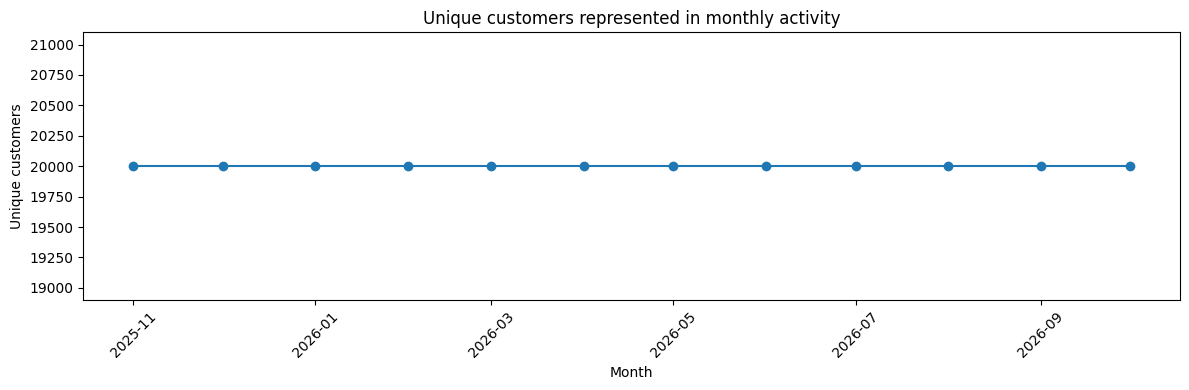

In [ ]:
# Monthly activity coverage

activity = data["activity"].copy()
activity["activity_month"] = pd.to_datetime(activity["activity_month"], errors="coerce")

monthly_coverage = activity.groupby("activity_month").agg(
    customer_count=("customer_id", "nunique"),
    mean_engagement=("engagement_score", "mean"),
    mean_active_days=("active_days", "mean"),
    total_logins=("login_count", "sum")
).reset_index()

display(monthly_coverage)

plt.figure(figsize=(12, 4))
plt.plot(monthly_coverage["activity_month"], monthly_coverage["customer_count"], marker="o")
plt.title("Unique customers represented in monthly activity")
plt.xlabel("Month")
plt.ylabel("Unique customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 5. Activity and engagement analysis

Explore the distribution of active days, logins, app sessions, service usage and engagement score.


,count,mean,std,min,25%,50%,75%,max
active_days,"240,000.00",12.67,9.14,0.00,5.00,11.00,20.00,30.00
login_count,"240,000.00",18.10,13.34,0.00,7.00,16.00,28.00,77.00
app_sessions,"240,000.00",11.65,8.82,0.00,4.00,10.00,18.00,51.00
service_usage_count,"240,000.00",9.70,7.45,0.00,3.00,8.00,15.00,44.00
engagement_score,"240,000.00",55.04,28.45,0.00,35.80,55.40,80.10,100.00


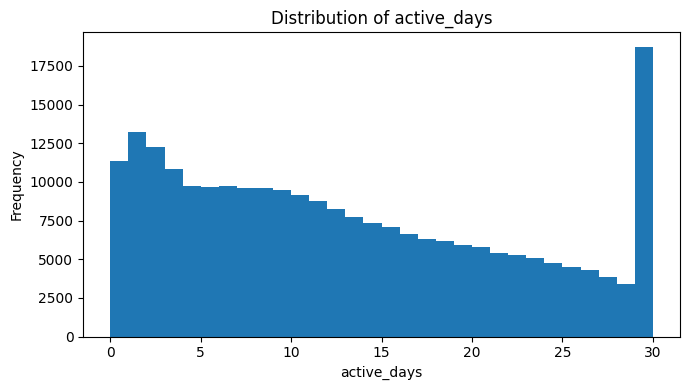

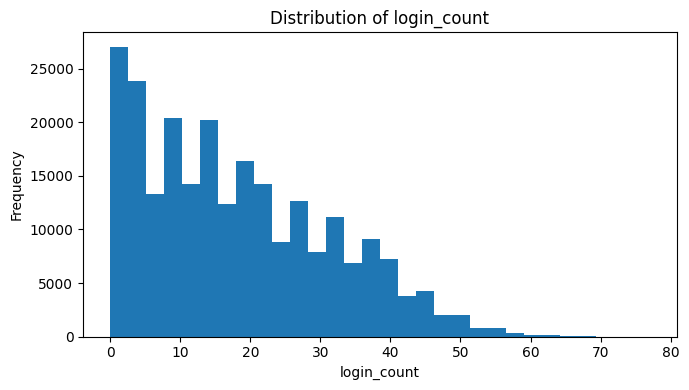

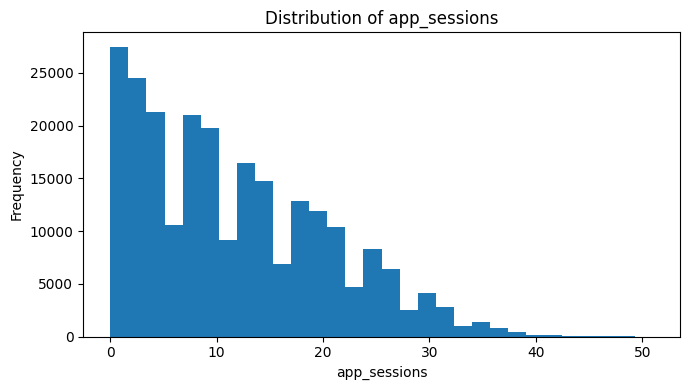

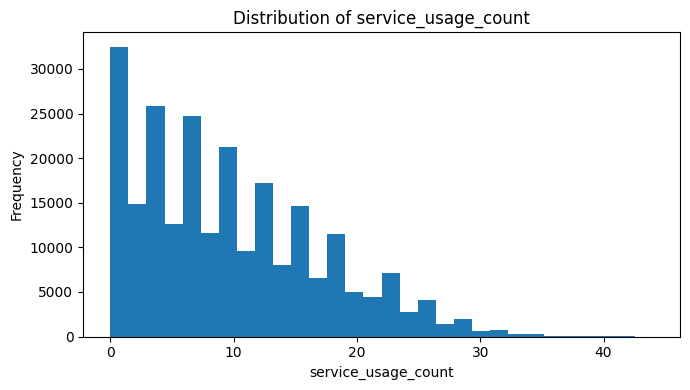

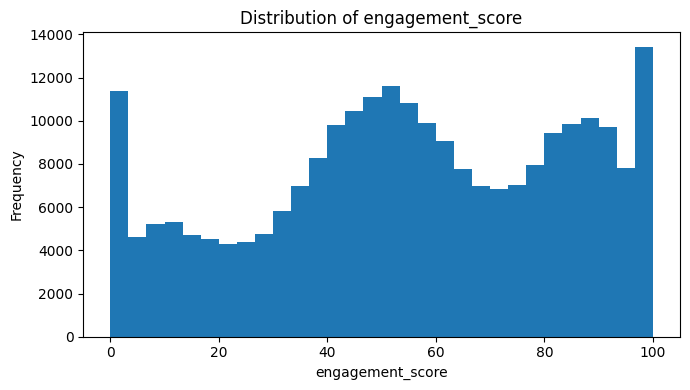

In [ ]:
activity_numeric = ["active_days", "login_count", "app_sessions",
                    "service_usage_count", "engagement_score"]

display(activity[activity_numeric].describe().T)

for col in activity_numeric:
    plt.figure(figsize=(7, 4))
    plt.hist(activity[col].dropna(), bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


## 6. Transaction analysis

Transaction analysis helps us understand frequency, value, transaction types and reversed transactions.

For customer profiling later, use successful transactions for customer spend/frequency features unless the business definition says otherwise.


,amount_inr
count,"221,203.00"
mean,331.31
std,373.33
min,50.00
25%,126.03
50%,222.34
75%,398.77
90%,685.73
95%,952.04
99%,"1,793.21"


,count
transaction_type,
UPI,77503
Card,48803
Bill Payment,28421
NEFT,26476
IMPS,22253
ATM,17747


,count
transaction_status,
Successful,217855
Reversed,3348


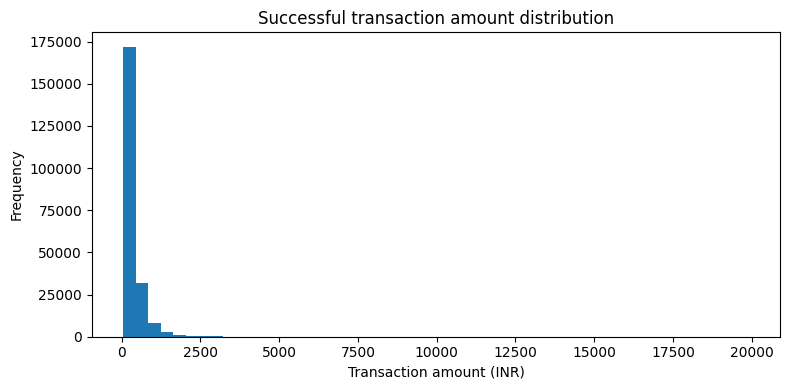

,transaction_date,transaction_count,total_value_inr,month
0,2025-11,18220,"6,072,122.68",2025-11
1,2025-12,18734,"6,255,366.03",2025-12
2,2026-01,18660,"6,134,516.48",2026-01
3,2026-02,17003,"5,648,876.72",2026-02
4,2026-03,18817,"6,204,910.42",2026-03
5,2026-04,18091,"5,981,795.69",2026-04
6,2026-05,18952,"6,253,534.76",2026-05
7,2026-06,18266,"6,050,001.41",2026-06
8,2026-07,18799,"6,241,109.54",2026-07
9,2026-08,18762,"6,203,268.81",2026-08


In [ ]:
transactions = data["transactions"].copy()
transactions["transaction_date"] = pd.to_datetime(transactions["transaction_date"], errors="coerce")

display(transactions[["amount_inr"]].describe(percentiles=[.25, .5, .75, .90, .95, .99]))
display(transactions["transaction_type"].value_counts().to_frame("count"))
display(transactions["transaction_status"].value_counts().to_frame("count"))

plt.figure(figsize=(8, 4))
plt.hist(transactions.loc[transactions["transaction_status"] == "Successful", "amount_inr"],
         bins=50)
plt.title("Successful transaction amount distribution")
plt.xlabel("Transaction amount (INR)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

monthly_tx = transactions.groupby(transactions["transaction_date"].dt.to_period("M")).agg(
    transaction_count=("transaction_id", "count"),
    total_value_inr=("amount_inr", "sum")
).reset_index()
monthly_tx["month"] = monthly_tx["transaction_date"].astype(str)

display(monthly_tx)


## 7. Billing and repayment analysis

Billing is a separate dimension from behavioural loyalty. A customer may be behaviourally loyal and still have an overdue bill.

Check billing status, days overdue, amount due and outstanding amount.


,count,mean,std,min,25%,50%,75%,max
amount_due_inr,"80,616.00","9,752.57","4,726.30","1,502.38","5,663.62","9,734.88","13,777.60","17,999.99"
amount_paid_inr,"80,616.00","8,140.35","5,640.38",0.00,"3,212.88","8,103.96","13,038.55","17,999.99"
days_overdue,"80,616.00",7.12,14.35,0.00,0.00,1.00,5.00,64.00
outstanding_inr,"80,616.00","1,612.22","4,095.42",0.00,0.00,0.00,0.00,"17,999.99"


,count
billing_status,
Paid on time,37115
Paid late,30143
Overdue,13358


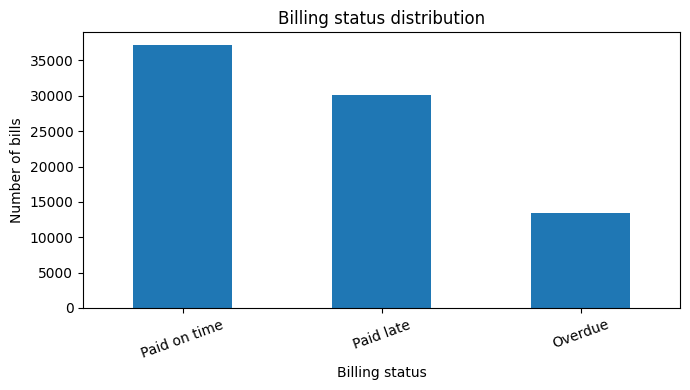

,count,mean,std,min,25%,50%,75%,max
days_overdue,"13,358.00",34.64,17.25,5.00,20.00,35.00,50.00,64.00
amount_due_inr,"13,358.00","9,729.83","4,715.93","1,502.38","5,651.31","9,781.77","13,665.65","17,999.99"
outstanding_inr,"13,358.00","9,729.83","4,715.93","1,502.38","5,651.31","9,781.77","13,665.65","17,999.99"


In [ ]:
billing = data["billing"].copy()
billing["due_date"] = pd.to_datetime(billing["due_date"], errors="coerce")
billing["payment_date"] = pd.to_datetime(billing["payment_date"], errors="coerce")
billing["outstanding_inr"] = (
    billing["amount_due_inr"] - billing["amount_paid_inr"]
).clip(lower=0)

display(billing[["amount_due_inr", "amount_paid_inr", "days_overdue",
                 "outstanding_inr"]].describe().T)
display(billing["billing_status"].value_counts().to_frame("count"))

plt.figure(figsize=(7, 4))
billing["billing_status"].value_counts().plot(kind="bar")
plt.title("Billing status distribution")
plt.xlabel("Billing status")
plt.ylabel("Number of bills")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

overdue = billing[billing["billing_status"] == "Overdue"]
display(overdue[["days_overdue", "amount_due_inr", "outstanding_inr"]].describe().T)


## 8. Campaign and communication analysis

These tables help us understand how customers respond to previous campaigns and which communication channels have been used.

Consent and communication frequency are operational controls. They should be used by the policy/guardrail layer, not as behavioural clustering features.


In [ ]:
campaigns = data["campaigns"]
communications = data["communications"]

display(campaigns["response_status"].value_counts(normalize=True).mul(100)
        .round(2).rename("percentage").to_frame())

display(communications["communication_purpose"].value_counts().to_frame("count"))
display(communications["channel"].value_counts().to_frame("count"))
display(communications["delivery_status"].value_counts().to_frame("count"))

campaign_response = campaigns.groupby("campaign_id").agg(
    interactions=("interaction_id", "count"),
    accepted=("response_status", lambda s: (s == "Accepted").sum())
)
campaign_response["acceptance_rate_pct"] = (
    100 * campaign_response["accepted"] / campaign_response["interactions"]
).round(2)

display(campaign_response.sort_values("acceptance_rate_pct", ascending=False))


,percentage
response_status,
Ignored,39.58
Accepted,30.31
Rejected,18.08
Viewed,12.04


,count
communication_purpose,
Marketing,17563
Service,11052
Billing,10018
Reward,6488
Onboarding,5032


,count
channel,
Email,12697
App,12540
SMS,12508
WhatsApp,12408


,count
delivery_status,
Delivered,21055
Opened,14050
Clicked,7945
Bounced,4129
Failed,2974


,interactions,accepted,acceptance_rate_pct
campaign_id,,,
CMP005,10626,3258,30.66
CMP003,10658,3256,30.55
CMP002,10872,3309,30.44
CMP001,10676,3241,30.36
CMP004,10684,3203,29.98
CMP006,10771,3216,29.86


## 9. Initial relationship checks

This is a preliminary correlation view for numeric activity fields. Correlation does not imply causation, and this is not yet the final feature-selection step.


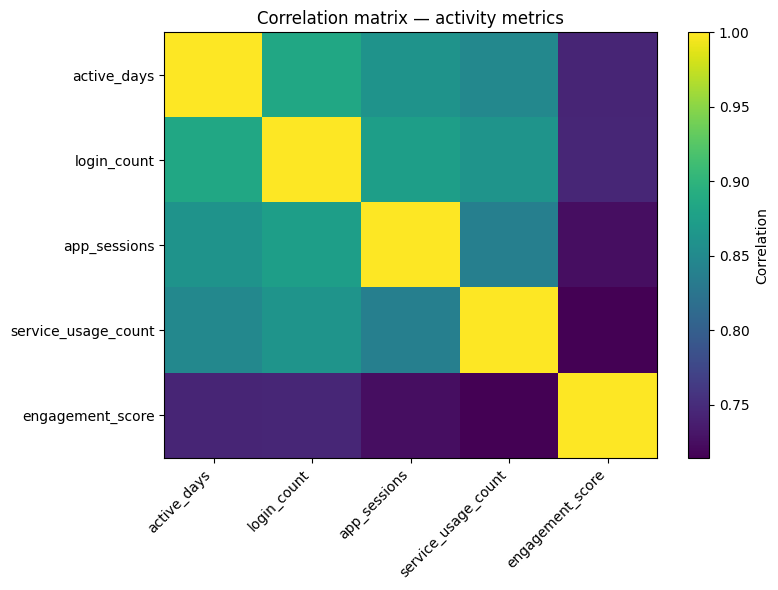

,active_days,login_count,app_sessions,service_usage_count,engagement_score
active_days,1.00,0.88,0.86,0.85,0.74
login_count,0.88,1.00,0.87,0.86,0.75
app_sessions,0.86,0.87,1.00,0.84,0.72
service_usage_count,0.85,0.86,0.84,1.00,0.71
engagement_score,0.74,0.75,0.72,0.71,1.00


In [ ]:
numeric_activity = activity[activity_numeric]
corr = numeric_activity.corr(numeric_only=True)

plt.figure(figsize=(8, 6))
plt.imshow(corr, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation matrix — activity metrics")
plt.tight_layout()
plt.show()

display(corr.round(2))


## 10. Synthetic validation column — inspect, do not train on it

The dataset includes `behavioural_archetype_for_validation` only to help us sanity-check whether the generated raw behaviour is coherent.

Do not use it:
- in feature engineering,
- in clustering,
- in model training,
- in SHAP input features.

You may inspect its distribution as a diagnostic only. In a real dataset, this ground-truth column would not exist.


In [ ]:
profile_reference = data["profile_reference"].copy()

if "behavioural_archetype_for_validation" in profile_reference.columns:
    display(profile_reference["behavioural_archetype_for_validation"]
            .value_counts().to_frame("customer_count"))


,customer_count
behavioural_archetype_for_validation,
loyal,6015
irregular,3962
declining,3923
dormant,3283
new,2817


## 11. EDA findings and handoff to Notebook 02

Complete this section after running the notebook.

### Record your findings
- Which tables have missing values?
- Are primary keys unique?
- Which tables contain only a subset of customers?
- Are transaction amounts skewed?
- What proportion of bills are overdue?
- Which campaign responses are most common?
- Which activity features appear redundant or strongly correlated?

### Decisions for Notebook 02 — Customer Profiling
1. Aggregate event-level data to one row per customer.
2. Use successful transactions for monetary and frequency features.
3. Build activity and engagement summaries over a defined observation window.
4. Keep billing status and behavioural segment separate.
5. Preserve consent and contact frequency for policy checks, not clustering.
6. Exclude customer identifiers and synthetic validation labels from model inputs.

**Expected output of Notebook 02:** a reproducible customer-level profile table built from the raw source tables.
